In [5]:

# CHURNIQ | Environment Setup

!pip -q install shap plotly

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings("ignore")

# Visualisation theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

print("CHURNIQ environment initialized successfully.")
print("Ready for data acquisition.")


CHURNIQ environment initialized successfully.
Ready for data acquisition.


In [6]:

# CHURNIQ | Data Acquisition

DATA_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/"
    "data/Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset successfully loaded!")
print("-" * 45)
print(f"Records: {df.shape[0]:,}")
print(f"Features: {df.shape[1]}")
print("-" * 45)

display(df.head())


Dataset successfully loaded!
---------------------------------------------
Records: 7,043
Features: 21
---------------------------------------------


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:

# CHURNIQ | Initial Data Audit

print("DATASET INFORMATION")
print("=" * 45)

print("\nDataset Shape:", df.shape)

print("\nColumn Data Types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing Values:")
display(
    df.isnull().sum()
      .to_frame("Missing Values")
      .sort_values("Missing Values", ascending=False)
)

print("\nDuplicate Records:", df.duplicated().sum())

print("\nChurn Distribution:")
display(df["Churn"].value_counts(normalize=True).mul(100).round(2))


DATASET INFORMATION

Dataset Shape: (7043, 21)

Column Data Types:


,Data Type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Missing Values:


,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate Records: 0

Churn Distribution:


,proportion
Churn,
No,73.46
Yes,26.54


In [ ]:
# 02 — Exploratory Data Analysis
### Understanding Customer Behaviour & Churn Patterns

This section explores customer demographics, service usage,
billing behaviour, contract preferences and historical churn.

**Objective:** Identify the key behavioural and financial
patterns associated with customer attrition.

In [8]:

# CHURNIQ | EDA Preparation

# Create a working copy
eda = df.copy()

# Clean column names
eda.columns = eda.columns.str.strip()

# Convert TotalCharges into numeric format
eda["TotalCharges"] = pd.to_numeric(
    eda["TotalCharges"], errors="coerce"
)

# Standardize target labels
eda["Churn"] = eda["Churn"].astype(str).str.strip()

# Numerical and categorical features
numeric_cols = [
    "tenure", "MonthlyCharges", "TotalCharges"
]

categorical_cols = [
    "Contract", "InternetService",
    "PaymentMethod", "SeniorCitizen",
    "PaperlessBilling", "Partner", "Dependents"
]

print("EDA DATA PREPARATION COMPLETE")
print("-" * 45)
print("Total customers:", len(eda))
print("Missing TotalCharges:", eda["TotalCharges"].isna().sum())
print("Churn categories:", eda["Churn"].unique())
print("Numerical features:", numeric_cols)
print("Categorical features:", categorical_cols)


EDA DATA PREPARATION COMPLETE
---------------------------------------------
Total customers: 7043
Missing TotalCharges: 11
Churn categories: ['No' 'Yes']
Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['Contract', 'InternetService', 'PaymentMethod', 'SeniorCitizen', 'PaperlessBilling', 'Partner', 'Dependents']


In [9]:

# CHURNIQ | Executive Metrics

total_customers = len(eda)

churned = (eda["Churn"] == "Yes").sum()
retained = (eda["Churn"] == "No").sum()

churn_rate = (churned / total_customers) * 100

monthly_revenue = eda["MonthlyCharges"].sum()

revenue_at_risk = eda.loc[
    eda["Churn"] == "Yes", "MonthlyCharges"
].sum()

print("=" * 55)
print("          CHURNIQ | BUSINESS PERFORMANCE")
print("=" * 55)

print(f"Total Customers       : {total_customers:,}")
print(f"Churned Customers     : {churned:,}")
print(f"Retained Customers    : {retained:,}")
print(f"Historical Churn Rate : {churn_rate:.2f}%")
print(f"Monthly Billing Total : ${monthly_revenue:,.2f}")
print(f"Monthly Revenue at Risk: ${revenue_at_risk:,.2f}")

print("=" * 55)


          CHURNIQ | BUSINESS PERFORMANCE
Total Customers       : 7,043
Churned Customers     : 1,869
Retained Customers    : 5,174
Historical Churn Rate : 26.54%
Monthly Billing Total : $456,116.60
Monthly Revenue at Risk: $139,130.85


In [10]:

# CHURNIQ | Churn Distribution

churn_counts = eda["Churn"].value_counts().reset_index()
churn_counts.columns = ["Customer Status", "Count"]

fig = px.pie(
    churn_counts,
    names="Customer Status",
    values="Count",
    hole=0.65,
    title="Customer Retention Overview",
    color="Customer Status",
    color_discrete_map={
        "Yes": "#EF6461",
        "No": "#35B7A5"
    }
)

fig.update_traces(
    textinfo="percent+label",
    textfont_size=14
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#101827",
    plot_bgcolor="#101827",
    font=dict(family="Arial", color="#F3F4F6"),
    title_x=0.5,
    height=480
)

fig.show()


In [11]:

# CHURNIQ | Contract-wise Churn Analysis

contract_churn = (
    eda.groupby("Contract", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="Churn Rate")
    .sort_values("Churn Rate", ascending=False)
)

fig = px.bar(
    contract_churn,
    x="Contract",
    y="Churn Rate",
    color="Churn Rate",
    color_continuous_scale=["#35B7A5", "#F4B860", "#EF6461"],
    text_auto=".2f",
    title="Historical Churn Rate by Contract Type"
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#101827",
    plot_bgcolor="#101827",
    font=dict(color="#F3F4F6"),
    yaxis_title="Churn Rate (%)",
    xaxis_title="Contract Type",
    title_x=0.5,
    coloraxis_showscale=False
)

fig.show()


In [12]:

# CHURNIQ | Customer Tenure Analysis

fig = px.histogram(
    eda,
    x="tenure",
    color="Churn",
    nbins=30,
    barmode="overlay",
    opacity=0.8,
    color_discrete_map={
        "Yes": "#EF6461",
        "No": "#35B7A5"
    },
    title="Customer Tenure Distribution by Churn Status",
    labels={
        "tenure": "Tenure (Months)",
        "count": "Number of Customers"
    }
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#101827",
    plot_bgcolor="#101827",
    font=dict(color="#F3F4F6"),
    title_x=0.5
)

fig.show()


In [13]:

# CHURNIQ | Billing Behaviour

fig = px.box(
    eda,
    x="Churn",
    y="MonthlyCharges",
    color="Churn",
    color_discrete_map={
        "Yes": "#EF6461",
        "No": "#35B7A5"
    },
    title="Monthly Charges: Churned vs Retained Customers",
    points="outliers"
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#101827",
    plot_bgcolor="#101827",
    font=dict(color="#F3F4F6"),
    title_x=0.5,
    xaxis_title="Customer Status",
    yaxis_title="Monthly Charges ($)"
)

fig.show()


In [14]:

# CHURNIQ | Business Insights

insight_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling",
    "SeniorCitizen"
]

insights = []

for feature in insight_features:
    result = (
        eda.groupby(feature, dropna=False)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Churn Rate (%)")
    )

    result["Feature"] = feature
    result.columns = ["Segment", "Churn Rate (%)", "Feature"]

    insights.append(result)

insights_df = pd.concat(insights, ignore_index=True)

insights_df = insights_df[
    ["Feature", "Segment", "Churn Rate (%)"]
].sort_values("Churn Rate (%)", ascending=False)

display(
    insights_df.style
    .format({"Churn Rate (%)": "{:.2f}%"})
    .background_gradient(
        subset=["Churn Rate (%)"],
        cmap="RdYlGn_r"
    )
)


,Feature,Segment,Churn Rate (%)
8,PaymentMethod,Electronic check,45.29%
0,Contract,Month-to-month,42.71%
4,InternetService,Fiber optic,41.89%
13,SeniorCitizen,1,41.68%
11,PaperlessBilling,Yes,33.57%
12,SeniorCitizen,0,23.61%
9,PaymentMethod,Mailed check,19.11%
3,InternetService,DSL,18.96%
6,PaymentMethod,Bank transfer (automatic),16.71%
10,PaperlessBilling,No,16.33%


In [15]:

# CHURNIQ | Automated EDA Summary Report

print("\n" + "=" * 60)
print("             CHURNIQ | ANALYTICAL REPORT")
print("=" * 60)

# 1. Overall churn
print("\n1. CUSTOMER CHURN")
print(f"Overall churn rate: {(eda['Churn'] == 'Yes').mean()*100:.2f}%")

# 2. Contract analysis
print("\n2. CHURN BY CONTRACT")
print(contract_churn.to_string(index=False))

# 3. Tenure analysis
print("\n3. AVERAGE TENURE")
print(
    eda.groupby("Churn")["tenure"]
    .mean().round(2).to_string()
)

# 4. Monthly charges
print("\n4. AVERAGE MONTHLY CHARGES")
print(
    eda.groupby("Churn")["MonthlyCharges"]
    .mean().round(2).to_string()
)

# 5. Highest churn segments
print("\n5. TOP CUSTOMER RISK SEGMENTS")
display(insights_df.head(10))

# 6. Save report
insights_df.to_csv(
    "churniq_eda_insights.csv", index=False
)

print("\nReport exported successfully!")
print("=" * 60)



             CHURNIQ | ANALYTICAL REPORT

1. CUSTOMER CHURN
Overall churn rate: 26.54%

2. CHURN BY CONTRACT
      Contract  Churn Rate
Month-to-month   42.709677
      One year   11.269518
      Two year    2.831858

3. AVERAGE TENURE
Churn
No     37.57
Yes    17.98

4. AVERAGE MONTHLY CHARGES
Churn
No     61.27
Yes    74.44

5. TOP CUSTOMER RISK SEGMENTS


,Feature,Segment,Churn Rate (%)
8,PaymentMethod,Electronic check,45.285412
0,Contract,Month-to-month,42.709677
4,InternetService,Fiber optic,41.892765
13,SeniorCitizen,1,41.681261
11,PaperlessBilling,Yes,33.565092
12,SeniorCitizen,0,23.606168
9,PaymentMethod,Mailed check,19.106700
3,InternetService,DSL,18.959108
6,PaymentMethod,Bank transfer (automatic),16.709845
10,PaperlessBilling,No,16.330084



Report exported successfully!


In [16]:

# CHURNIQ | Feature Preparation

ml_df = eda.copy()

# Remove customer identifier
ml_df.drop(columns=["customerID"], inplace=True)

# Convert target into binary values
ml_df["Churn"] = ml_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Remove rows with missing target
ml_df = ml_df.dropna(subset=["Churn"])

print("Feature preparation complete")
print("Dataset shape:", ml_df.shape)
print("\nTarget distribution:")
print(ml_df["Churn"].value_counts())


Feature preparation complete
Dataset shape: (7043, 20)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [17]:

# CHURNIQ | Feature Classification

X = ml_df.drop(columns=["Churn"])
y = ml_df["Churn"].astype(int)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTotal features:", len(X.columns))


Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total features: 19


In [18]:

# CHURNIQ | Train / Validation / Test Split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("DATA SPLIT SUMMARY")
print("-" * 40)

for name, data in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(
        f"{name}: {len(data)} records | "
        f"Churn rate: {data.mean()*100:.2f}%"
    )


DATA SPLIT SUMMARY
----------------------------------------
Training: 4930 records | Churn rate: 26.53%
Validation: 1056 records | Churn rate: 26.52%
Testing: 1057 records | Churn rate: 26.58%


In [19]:

# CHURNIQ | Preprocessing Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSING COMPLETE")
print("Training matrix:", X_train_processed.shape)
print("Validation matrix:", X_val_processed.shape)
print("Testing matrix:", X_test_processed.shape)


PREPROCESSING COMPLETE
Training matrix: (4930, 45)
Validation matrix: (1056, 45)
Testing matrix: (1057, 45)


In [ ]:
# 04 — Predictive Model Development
### Customer Churn Classification

We compare three supervised learning algorithms
to identify customers with a high probability of churn.

Evaluation is performed on a separate validation set.
The final test set remains untouched until model selection.

In [20]:

# CHURNIQ | Model Initialization

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)

from scipy import sparse

# Convert sparse matrices to dense only for Gradient Boosting
X_train_dense = (
    X_train_processed.toarray()
    if sparse.issparse(X_train_processed)
    else X_train_processed
)

X_val_dense = (
    X_val_processed.toarray()
    if sparse.issparse(X_val_processed)
    else X_val_processed
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Three ML models initialized successfully.")


Three ML models initialized successfully.


In [21]:

# CHURNIQ | Model Training & Validation

results = []
trained_models = {}

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

for name, model in models.items():

    print(f"\nTraining: {name}")

    if name == "Gradient Boosting":
        model.fit(
            X_train_dense,
            y_train,
            sample_weight=sample_weights
        )
        X_val_model = X_val_dense

    else:
        model.fit(X_train_processed, y_train)
        X_val_model = X_val_processed

    trained_models[name] = model

    # Probability predictions
    probabilities = model.predict_proba(X_val_model)[:, 1]

    # Standard classification threshold
    predictions = (probabilities >= 0.50).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        )
    })

    print("Completed!")

results_df = pd.DataFrame(results)

print("\nMODEL TRAINING COMPLETED")



Training: Logistic Regression
Completed!

Training: Random Forest
Completed!

Training: Gradient Boosting
Completed!

MODEL TRAINING COMPLETED


In [22]:

# CHURNIQ | Model Comparison

display(
    results_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).style.format({
        col: "{:.4f}"
        for col in results_df.select_dtypes("number").columns
    }).highlight_max(
        axis=0,
        color="#D1FAE5"
    )
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Balanced Accuracy
2,Gradient Boosting,0.7491,0.5168,0.8250,0.6355,0.8474,0.6421,0.7733
0,Logistic Regression,0.7396,0.5055,0.8143,0.6238,0.8447,0.6308,0.7635
1,Random Forest,0.7746,0.5614,0.6857,0.6174,0.8323,0.6072,0.7462


In [23]:

# CHURNIQ | Model Performance Dashboard

metrics_to_plot = [
    "Precision", "Recall", "F1 Score", "ROC-AUC", "PR-AUC"
]

plot_data = results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

fig = px.bar(
    plot_data,
    x="Metric",
    y="Score",
    color="Model",
    barmode="group",
    text_auto=".3f",
    title="Comparative Performance of Churn Prediction Models",
    color_discrete_sequence=[
        "#35B7A5", "#8B7CF6", "#F4B860"
    ]
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#101827",
    plot_bgcolor="#101827",
    font=dict(color="#F3F4F6"),
    title_x=0.5,
    yaxis=dict(range=[0, 1]),
    height=520
)

fig.show()


In [24]:

# CHURNIQ | Model Selection & Threshold Optimization

from sklearn.metrics import precision_recall_curve

# Select model with highest validation PR-AUC
best_model_name = results_df.sort_values(
    "PR-AUC", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

if best_model_name == "Gradient Boosting":
    X_val_best = X_val_dense
else:
    X_val_best = X_val_processed

val_probabilities = best_model.predict_proba(
    X_val_best
)[:, 1]

# Calculate precision and recall at different thresholds
precision_values, recall_values, thresholds = (
    precision_recall_curve(y_val, val_probabilities)
)

# Calculate F2 score
f2_scores = (
    5 * precision_values[:-1] * recall_values[:-1]
    /
    (4 * precision_values[:-1] + recall_values[:-1] + 1e-10)
)

best_threshold_index = np.argmax(f2_scores)
best_threshold = thresholds[best_threshold_index]

print("MODEL SELECTION")
print("-" * 45)
print("Selected model:", best_model_name)
print(f"Validation PR-AUC: {average_precision_score(y_val, val_probabilities):.4f}")
print(f"Optimized threshold: {best_threshold:.4f}")
print(f"Validation precision: {precision_values[best_threshold_index]:.4f}")
print(f"Validation recall: {recall_values[best_threshold_index]:.4f}")
print(f"Validation F2-score: {f2_scores[best_threshold_index]:.4f}")


MODEL SELECTION
---------------------------------------------
Selected model: Gradient Boosting
Validation PR-AUC: 0.6421
Optimized threshold: 0.2946
Validation precision: 0.4385
Validation recall: 0.9429
Validation F2-score: 0.7666


In [25]:

# CHURNIQ | Final Test Evaluation

from sklearn.metrics import classification_report, confusion_matrix

if best_model_name == "Gradient Boosting":
    X_test_best = (
        X_test_processed.toarray()
        if sparse.issparse(X_test_processed)
        else X_test_processed
    )
else:
    X_test_best = X_test_processed

test_probabilities = best_model.predict_proba(
    X_test_best
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("FINAL TEST RESULTS")
print("=" * 50)

print("Selected model:", best_model_name)
print(f"Threshold: {best_threshold:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Retained", "Churned"],
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))

print("PR-AUC:", round(
    average_precision_score(y_test, test_probabilities), 4
))


FINAL TEST RESULTS
Selected model: Gradient Boosting
Threshold: 0.2946

Classification Report:
              precision    recall  f1-score   support

    Retained       0.94      0.58      0.72       776
     Churned       0.43      0.89      0.58       281

    accuracy                           0.66      1057
   macro avg       0.68      0.73      0.65      1057
weighted avg       0.80      0.66      0.68      1057

ROC-AUC: 0.8357
PR-AUC: 0.6592


In [26]:

# CHURNIQ | Confusion Matrix

cm = confusion_matrix(y_test, test_predictions)

fig = px.imshow(
    cm,
    text_auto=True,
    x=["Predicted Retained", "Predicted Churned"],
    y=["Actual Retained", "Actual Churned"],
    color_continuous_scale="Teal",
    title="CHURNIQ | Final Model Confusion Matrix",
    aspect="auto"
)

fig.update_layout(
    template="plotly_dark",
    paper_bgcolor="#101827",
    font=dict(color="#F3F4F6"),
    title_x=0.5,
    height=450
)

fig.show()


In [27]:

# CHURNIQ | Export Model Results

results_df.to_csv(
    "churniq_model_comparison.csv",
    index=False
)

final_metrics = pd.DataFrame([{
    "Selected Model": best_model_name,
    "Decision Threshold": best_threshold,
    "Test ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Test PR-AUC": average_precision_score(y_test, test_probabilities),
    "Test Precision": precision_score(y_test, test_predictions),
    "Test Recall": recall_score(y_test, test_predictions),
    "Test F1": f1_score(y_test, test_predictions)
}])

final_metrics.to_csv(
    "churniq_final_metrics.csv",
    index=False
)

print("CHURNIQ MODEL REPORTS EXPORTED")
print("1. churniq_model_comparison.csv")
print("2. churniq_final_metrics.csv")


CHURNIQ MODEL REPORTS EXPORTED
1. churniq_model_comparison.csv
2. churniq_final_metrics.csv


In [ ]:
# 05 — Explainable Artificial Intelligence
### Understanding Model Decisions with SHAP

This section uses SHAP (SHapley Additive exPlanations)
to interpret the selected churn prediction model.

The analysis covers global feature importance,
feature-level impact and individual customer predictions.

In [28]:

# CHURNIQ | SHAP Environment Setup

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy import sparse

# Convert training and test matrices to dense format
# if required by the explanation workflow

X_train_shap = (
    X_train_processed.toarray()
    if sparse.issparse(X_train_processed)
    else np.asarray(X_train_processed)
)

X_test_shap = (
    X_test_processed.toarray()
    if sparse.issparse(X_test_processed)
    else np.asarray(X_test_processed)
)

# Retrieve feature names after encoding
feature_names = preprocessor.get_feature_names_out()

# Create labelled DataFrames
X_train_shap_df = pd.DataFrame(
    X_train_shap,
    columns=feature_names
)

X_test_shap_df = pd.DataFrame(
    X_test_shap,
    columns=feature_names
)

print("SHAP environment ready.")
print("Number of transformed features:", len(feature_names))
print("Training data:", X_train_shap_df.shape)
print("Test data:", X_test_shap_df.shape)


SHAP environment ready.
Number of transformed features: 45
Training data: (4930, 45)
Test data: (1057, 45)


In [29]:

# CHURNIQ | SHAP Explanation Engine

# Use reproducible samples
background = X_train_shap_df.sample(
    n=min(50, len(X_train_shap_df)),
    random_state=42
)

explain_data = X_test_shap_df.sample(
    n=min(100, len(X_test_shap_df)),
    random_state=42
)

# Function returning churn probability
def predict_churn_probability(data):
    data = pd.DataFrame(data, columns=feature_names)
    return best_model.predict_proba(data)[:, 1]

# Build model-agnostic SHAP explainer
masker = shap.maskers.Independent(
    background,
    max_samples=50
)

explainer = shap.Explainer(
    predict_churn_probability,
    masker,
    algorithm="permutation",
    feature_names=list(feature_names)
)

# Calculate SHAP values
shap_values = explainer(
    explain_data,
    max_evals=2 * len(feature_names) + 1
)

print("SHAP calculations completed.")
print("Explained customers:", len(explain_data))
print("Explained features:", len(feature_names))


SHAP calculations completed.
Explained customers: 100
Explained features: 45


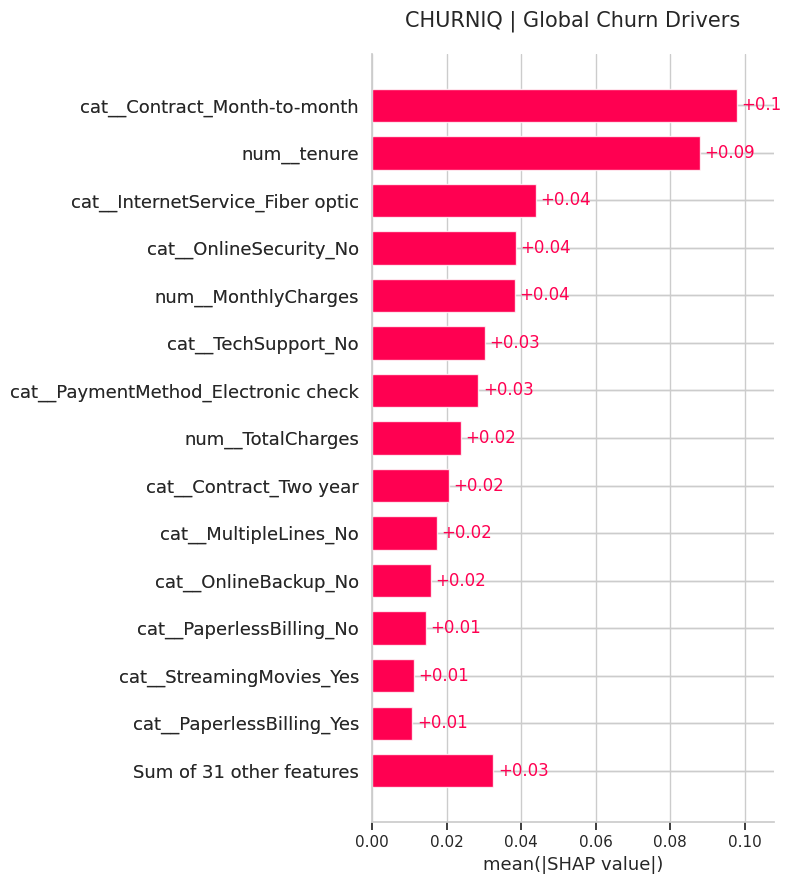

In [30]:

# CHURNIQ | Global Feature Importance

shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "CHURNIQ | Global Churn Drivers",
    fontsize=15,
    pad=20
)

plt.tight_layout()
plt.savefig(
    "churniq_global_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


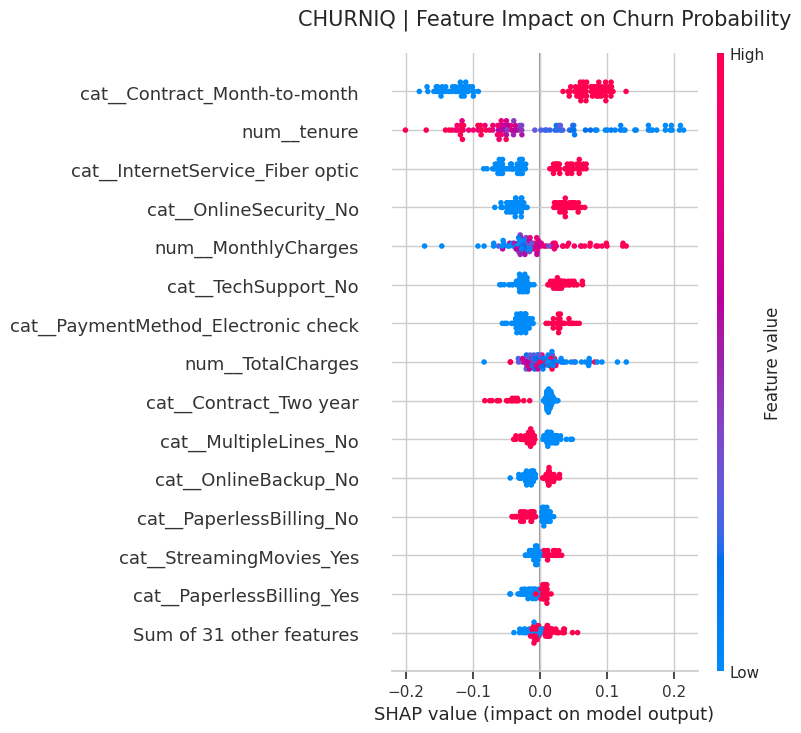

In [31]:

# CHURNIQ | SHAP Feature Impact Analysis

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title(
    "CHURNIQ | Feature Impact on Churn Probability",
    fontsize=15,
    pad=20
)

plt.tight_layout()

plt.savefig(
    "churniq_shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [35]:

# CHURNIQ | Individual Customer Risk Analysis

# Predict churn probability for all customers in the SHAP sample
individual_probabilities = predict_churn_probability(explain_data)

# Find the highest-risk customer
risk_idx = int(np.argmax(individual_probabilities))
risk_probability = individual_probabilities[risk_idx]

# Retrieve the matching original customer using positional indexing
# This avoids the KeyError caused by mismatched index labels.
original_customer = X_test.iloc[
    X_test.index.get_indexer([explain_data.index[risk_idx]])[0]
]

print("=" * 55)
print("       CHURNIQ | HIGH-RISK CUSTOMER PROFILE")
print("=" * 55)

print(f"Predicted Churn Probability: {risk_probability:.2%}")
print(f"Decision Threshold: {best_threshold:.2%}")

print(
    "Model Classification:",
    "HIGH RISK" if risk_probability >= best_threshold
    else "BELOW THRESHOLD"
)

print("\nCUSTOMER DETAILS")
print("-" * 55)

display(original_customer.to_frame("Customer Details"))


       CHURNIQ | HIGH-RISK CUSTOMER PROFILE
Predicted Churn Probability: 90.59%
Decision Threshold: 29.46%
Model Classification: HIGH RISK

CUSTOMER DETAILS
-------------------------------------------------------


,Customer Details
gender,Female
SeniorCitizen,1
Partner,No
Dependents,No
tenure,46
PhoneService,Yes
MultipleLines,Yes
InternetService,Fiber optic
OnlineSecurity,No
OnlineBackup,Yes


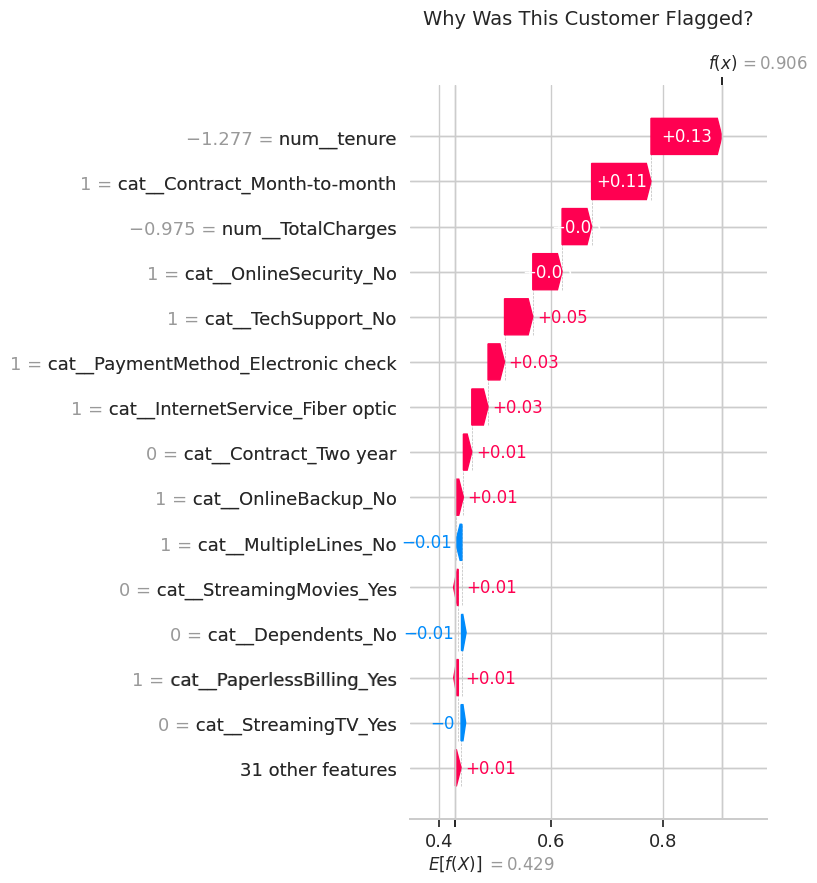

In [36]:

# CHURNIQ | Individual SHAP Waterfall

shap.plots.waterfall(
    shap_values[risk_idx],
    max_display=15,
    show=False
)

plt.title(
    "Why Was This Customer Flagged?",
    fontsize=14,
    pad=20
)

plt.tight_layout()

plt.savefig(
    "churniq_individual_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [37]:

# CHURNIQ | Ranked Churn Drivers

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance["Rank"] = (
    shap_importance.index + 1
)

display(
    shap_importance[
        ["Rank", "Feature", "Mean Absolute SHAP"]
    ].head(15).style.format({
        "Mean Absolute SHAP": "{:.5f}"
    }).background_gradient(
        subset=["Mean Absolute SHAP"],
        cmap="Blues"
    )
)

shap_importance.to_csv(
    "churniq_shap_feature_importance.csv",
    index=False
)

print("SHAP importance report exported.")


,Rank,Feature,Mean Absolute SHAP
0,1,cat__Contract_Month-to-month,0.09778
1,2,num__tenure,0.08788
2,3,cat__InternetService_Fiber optic,0.04401
3,4,cat__OnlineSecurity_No,0.03871
4,5,num__MonthlyCharges,0.03834
5,6,cat__TechSupport_No,0.03031
6,7,cat__PaymentMethod_Electronic check,0.02854
7,8,num__TotalCharges,0.02376
8,9,cat__Contract_Two year,0.02066
9,10,cat__MultipleLines_No,0.01744


SHAP importance report exported.


In [38]:

# CHURNIQ | Export Explainability Assets

import os
import zipfile

files_to_save = [
    "churniq_global_feature_importance.png",
    "churniq_shap_beeswarm.png",
    "churniq_individual_explanation.png",
    "churniq_shap_feature_importance.csv"
]

with zipfile.ZipFile(
    "CHURNIQ_Explainability_Reports.zip", "w"
) as zip_file:

    for file in files_to_save:
        if os.path.exists(file):
            zip_file.write(file)

print("Explainability assets packaged successfully.")
print("File: CHURNIQ_Explainability_Reports.zip")


Explainability assets packaged successfully.
File: CHURNIQ_Explainability_Reports.zip


In [39]:

# ============================================================
# CHURNIQ | PHASE 6: MODEL BUNDLE & PREDICTION ENGINE
# ============================================================

import os
import joblib
import pandas as pd
import numpy as np

# Create model directory
os.makedirs("models", exist_ok=True)

# Save everything required for future predictions
model_bundle = {
    "model": best_model,
    "preprocessor": preprocessor,
    "threshold": float(best_threshold),
    "model_name": best_model_name,
    "feature_names": list(X.columns)
}

MODEL_PATH = "models/churniq_model_bundle.joblib"

joblib.dump(model_bundle, MODEL_PATH)

print("=" * 55)
print("          CHURNIQ | MODEL ENGINE")
print("=" * 55)
print("Model:", best_model_name)
print(f"Decision Threshold: {best_threshold:.2%}")
print("Preprocessing pipeline: Saved")
print("Prediction model: Saved")
print("Model bundle:", MODEL_PATH)
print("\nEngine components saved successfully!")


          CHURNIQ | MODEL ENGINE
Model: Gradient Boosting
Decision Threshold: 29.46%
Preprocessing pipeline: Saved
Prediction model: Saved
Model bundle: models/churniq_model_bundle.joblib

Engine components saved successfully!


In [40]:

# ============================================================
# CHURNIQ | CUSTOMER CHURN PREDICTION FUNCTION
# ============================================================

# Load saved model bundle
engine = joblib.load("models/churniq_model_bundle.joblib")

def predict_customer_churn(customer_data):

    # Accept either a dictionary or a DataFrame
    if isinstance(customer_data, dict):
        customer_data = pd.DataFrame([customer_data])

    elif not isinstance(customer_data, pd.DataFrame):
        raise TypeError("Input must be a dictionary or pandas DataFrame.")

    # Identify required input columns
    required_features = engine["feature_names"]

    # Check for missing columns
    missing_features = [
        col for col in required_features
        if col not in customer_data.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing customer information: {missing_features}"
        )

    # Keep only the required columns in the correct order
    customer_data = customer_data[required_features].copy()

    # Apply the same preprocessing used during model training
    processed_data = engine["preprocessor"].transform(customer_data)

    # Predict churn probability
    probabilities = engine["model"].predict_proba(processed_data)[:, 1]

    # Apply the validation-selected threshold
    predictions = (
        probabilities >= engine["threshold"]
    ).astype(int)

    # Prepare readable results
    results = pd.DataFrame({
        "Churn Probability": probabilities,
        "Prediction": [
            "Likely to Churn" if p == 1 else "Likely to Stay"
            for p in predictions
        ],
        "Risk Classification": [
            "HIGH RISK" if p == 1 else "BELOW THRESHOLD"
            for p in predictions
        ]
    })

    return results


print("CHURNIQ prediction function created successfully!")


CHURNIQ prediction function created successfully!


In [41]:

# ============================================================
# CHURNIQ | ENGINE TEST
# ============================================================

# Select one unseen customer from the test dataset
test_customer = X_test.iloc[[0]]

# Generate prediction
test_result = predict_customer_churn(test_customer)

print("=" * 55)
print("          CHURNIQ | CUSTOMER PREDICTION")
print("=" * 55)

print("\nCUSTOMER INFORMATION")
display(test_customer.T.rename(columns={test_customer.index[0]: "Value"}))

print("\nPREDICTION RESULT")
display(test_result)

print("\nEngine test completed successfully!")


          CHURNIQ | CUSTOMER PREDICTION

CUSTOMER INFORMATION


,Value
gender,Male
SeniorCitizen,1
Partner,No
Dependents,No
tenure,17
PhoneService,Yes
MultipleLines,No
InternetService,DSL
OnlineSecurity,No
OnlineBackup,No



PREDICTION RESULT


,Churn Probability,Prediction,Risk Classification
0,0.666275,Likely to Churn,HIGH RISK



Engine test completed successfully!


In [42]:

# ============================================================
# CHURNIQ | BULK PREDICTION TEST
# ============================================================

# Select 10 customers from the test dataset
sample_customers = X_test.iloc[:10].copy()

# Generate predictions
bulk_results = predict_customer_churn(sample_customers)

# Combine customer details and predictions
bulk_report = pd.concat([
    sample_customers.reset_index(drop=True),
    bulk_results.reset_index(drop=True)
], axis=1)

print("CHURNIQ | BULK CUSTOMER ANALYSIS")
display(bulk_report)

print("\nTOTAL CUSTOMERS ANALYSED:", len(bulk_report))
print(
    "HIGH-RISK CUSTOMERS:",
    (bulk_results["Risk Classification"] == "HIGH RISK").sum()
)


CHURNIQ | BULK CUSTOMER ANALYSIS


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn Probability,Prediction,Risk Classification
0,Male,1,No,No,17,Yes,No,DSL,No,No,...,No,No,Month-to-month,Yes,Electronic check,45.05,770.60,0.666275,Likely to Churn,HIGH RISK
1,Male,0,Yes,No,43,Yes,No,DSL,No,No,...,Yes,No,One year,Yes,Mailed check,56.35,2391.15,0.245918,Likely to Stay,BELOW THRESHOLD
2,Female,0,Yes,Yes,72,Yes,Yes,DSL,No,No,...,Yes,Yes,Two year,Yes,Bank transfer (automatic),76.80,5468.45,0.115519,Likely to Stay,BELOW THRESHOLD
3,Male,0,No,No,54,Yes,No,Fiber optic,Yes,No,...,Yes,No,Month-to-month,No,Mailed check,89.80,4667.00,0.390905,Likely to Churn,HIGH RISK
4,Male,0,Yes,Yes,63,No,No phone service,DSL,No,Yes,...,No,No,Two year,No,Bank transfer (automatic),39.35,2395.05,0.078155,Likely to Stay,BELOW THRESHOLD
5,Male,0,No,No,9,Yes,No,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,No,Mailed check,19.85,178.80,0.256084,Likely to Stay,BELOW THRESHOLD
6,Male,0,Yes,Yes,72,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,Two year,Yes,Credit card (automatic),25.10,1790.80,0.023984,Likely to Stay,BELOW THRESHOLD
7,Female,0,Yes,Yes,66,Yes,Yes,Fiber optic,No,No,...,No,No,One year,Yes,Bank transfer (automatic),74.25,4859.25,0.194535,Likely to Stay,BELOW THRESHOLD
8,Male,0,No,Yes,19,Yes,Yes,No,No internet service,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Credit card (automatic),24.10,439.20,0.219966,Likely to Stay,BELOW THRESHOLD
9,Female,1,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,69.60,69.60,0.910932,Likely to Churn,HIGH RISK



TOTAL CUSTOMERS ANALYSED: 10
HIGH-RISK CUSTOMERS: 3


In [43]:
!pip -q install streamlit plotly joblib

In [44]:

import os

os.makedirs("app", exist_ok=True)

dashboard_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import joblib

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="CHURNIQ | Customer Intelligence",
    page_icon="📊",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --------------------------------------------------
# DESIGN SYSTEM
# --------------------------------------------------

st.markdown("""
<style>
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');

html, body, [class*="css"] {
    font-family: 'Inter', sans-serif;
}

.stApp {
    background: #0B1020;
    color: #F1F5F9;
}

[data-testid="stSidebar"] {
    background: #11182B;
    border-right: 1px solid #26334D;
}

h1, h2, h3 {
    color: #F8FAFC !important;
}

p, label, span {
    color: #CBD5E1;
}

.metric-card {
    background: linear-gradient(135deg, #17243B, #111A2D);
    border: 1px solid #293B58;
    border-radius: 14px;
    padding: 20px;
    min-height: 115px;
}

.metric-label {
    color: #94A3B8;
    font-size: 13px;
    margin-bottom: 10px;
}

.metric-value {
    color: #F8FAFC;
    font-size: 29px;
    font-weight: 800;
}

.metric-note {
    color: #2DD4BF;
    font-size: 12px;
    margin-top: 5px;
}

.hero {
    background: linear-gradient(110deg, #172B48, #17213A, #28204B);
    border: 1px solid #344767;
    border-radius: 18px;
    padding: 28px;
    margin-bottom: 25px;
}

.hero-title {
    font-size: 34px;
    font-weight: 800;
    color: white;
}

.hero-subtitle {
    color: #B7C7DE;
    font-size: 14px;
}

div[data-testid="stForm"] {
    background: #111A2D;
    border: 1px solid #293B58;
    padding: 20px;
    border-radius: 14px;
}

.stButton > button {
    background: #14B8A6;
    color: #071521;
    border: none;
    border-radius: 9px;
    font-weight: 700;
    min-height: 42px;
}

.stButton > button:hover {
    background: #2DD4BF;
    color: #071521;
}

div[data-testid="stDataFrame"] {
    border: 1px solid #293B58;
    border-radius: 10px;
}

hr {
    border-color: #26334D;
}
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# MODEL ENGINE
# --------------------------------------------------

MODEL_PATH = "models/churniq_model_bundle.joblib"

@st.cache_resource
def load_engine():
    return joblib.load(MODEL_PATH)

try:
    engine = load_engine()
except Exception as error:
    st.error(f"Could not load the model: {error}")
    st.stop()

FEATURES = engine["feature_names"]
MODEL = engine["model"]
PREPROCESSOR = engine["preprocessor"]
THRESHOLD = engine["threshold"]

# --------------------------------------------------
# PREDICTION FUNCTION
# --------------------------------------------------

def predict_customers(data):
    data = data[FEATURES].copy()

    processed = PREPROCESSOR.transform(data)

    probabilities = MODEL.predict_proba(processed)[:, 1]

    predictions = (probabilities >= THRESHOLD).astype(int)

    results = pd.DataFrame({
        "Churn Probability": probabilities,
        "Prediction": [
            "Likely to Churn" if p else "Likely to Stay"
            for p in predictions
        ],
        "Risk Classification": [
            "HIGH RISK" if p else "BELOW THRESHOLD"
            for p in predictions
        ]
    })

    return results

# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

with st.sidebar:
    st.markdown("# CHURNIQ")
    st.caption("CUSTOMER INTELLIGENCE PLATFORM")
    st.markdown("---")

    page = st.radio(
        "NAVIGATION",
        [
            "Overview",
            "Customer Prediction",
            "Batch Analysis",
            "About the Model"
        ]
    )

    st.markdown("---")
    st.markdown("**MODEL STATUS**")
    st.success("Prediction engine loaded")
    st.caption(f"Model: {engine['model_name']}")
    st.caption(f"Decision threshold: {THRESHOLD:.1%}")

    st.markdown("---")
    st.caption("CHURNIQ • Customer Retention Intelligence")

# --------------------------------------------------
# HEADER
# --------------------------------------------------

st.markdown("""
<div class="hero">
    <div class="hero-title">Customer Intelligence, Simplified.</div>
    <div class="hero-subtitle">
        Predict churn. Identify high-risk customers.
        Make smarter retention decisions.
    </div>
</div>
""", unsafe_allow_html=True)

# --------------------------------------------------
# OVERVIEW
# --------------------------------------------------

if page == "Overview":

    st.subheader("Business Overview")
    st.caption("Explore the IBM Telco customer dataset.")

    @st.cache_data
    def load_dataset():
        url = (
            "https://raw.githubusercontent.com/IBM/"
            "telco-customer-churn-on-icp4d/master/"
            "data/Telco-Customer-Churn.csv"
        )
        data = pd.read_csv(url)
        data["TotalCharges"] = pd.to_numeric(
            data["TotalCharges"], errors="coerce"
        )
        return data

    try:
        data = load_dataset()
    except Exception:
        st.warning(
            "The sample dataset could not be loaded. "
            "Check your internet connection."
        )
        st.stop()

    total_customers = len(data)
    churn_count = (data["Churn"] == "Yes").sum()
    churn_rate = churn_count / total_customers * 100
    avg_monthly = data["MonthlyCharges"].mean()
    avg_tenure = data["tenure"].mean()

    c1, c2, c3, c4 = st.columns(4)

    metrics = [
        (c1, "TOTAL CUSTOMERS", f"{total_customers:,}", "Dataset records"),
        (c2, "CHURNED CUSTOMERS", f"{churn_count:,}", "Customers lost"),
        (c3, "CHURN RATE", f"{churn_rate:.1f}%", "Historical churn"),
        (c4, "AVG. MONTHLY CHARGE", f"${avg_monthly:.2f}", "Per customer")
    ]

    for col, label, value, note in metrics:
        with col:
            st.markdown(f"""
            <div class="metric-card">
                <div class="metric-label">{label}</div>
                <div class="metric-value">{value}</div>
                <div class="metric-note">{note}</div>
            </div>
            """, unsafe_allow_html=True)

    st.markdown("")
    left, right = st.columns(2)

    with left:
        st.markdown("### Customer Churn Distribution")
        churn_chart = data["Churn"].value_counts().reset_index()
        churn_chart.columns = ["Status", "Customers"]

        fig = px.pie(
            churn_chart,
            names="Status",
            values="Customers",
            hole=0.68,
            color="Status",
            color_discrete_map={
                "Yes": "#FB7185",
                "No": "#2DD4BF"
            }
        )
        fig.update_layout(
            template="plotly_dark",
            paper_bgcolor="rgba(0,0,0,0)",
            plot_bgcolor="rgba(0,0,0,0)",
            margin=dict(t=20, b=20, l=10, r=10),
            legend_title=""
        )
        st.plotly_chart(fig, use_container_width=True)

    with right:
        st.markdown("### Churn by Contract Type")

        contract_data = (
            data.groupby("Contract", observed=True)["Churn"]
            .apply(lambda x: (x == "Yes").mean() * 100)
            .reset_index(name="Churn Rate")
        )

        fig = px.bar(
            contract_data,
            x="Contract",
            y="Churn Rate",
            color="Contract",
            text_auto=".1f",
            color_discrete_sequence=["#2DD4BF", "#818CF8", "#FB7185"]
        )
        fig.update_layout(
            template="plotly_dark",
            paper_bgcolor="rgba(0,0,0,0)",
            plot_bgcolor="rgba(0,0,0,0)",
            showlegend=False,
            yaxis_title="Churn rate (%)",
            xaxis_title=""
        )
        st.plotly_chart(fig, use_container_width=True)

    st.markdown("### Customer Tenure Distribution")

    fig = px.histogram(
        data,
        x="tenure",
        color="Churn",
        nbins=30,
        barmode="overlay",
        opacity=0.8,
        color_discrete_map={
            "Yes": "#FB7185",
            "No": "#2DD4BF"
        }
    )
    fig.update_layout(
        template="plotly_dark",
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        xaxis_title="Tenure (months)",
        yaxis_title="Number of customers"
    )
    st.plotly_chart(fig, use_container_width=True)

    st.info(
        "These overview metrics describe the historical dataset. "
        "They are not live company customer records."
    )

# --------------------------------------------------
# SINGLE CUSTOMER PREDICTION
# --------------------------------------------------

elif page == "Customer Prediction":

    st.subheader("Individual Customer Risk Assessment")
    st.caption(
        "Enter customer details to estimate their probability of churn."
    )

    with st.form("customer_form"):

        st.markdown("### Personal Information")
        a, b, c = st.columns(3)

        with a:
            gender = st.selectbox("Gender", ["Male", "Female"])
        with b:
            senior = st.selectbox("Senior Citizen", [0, 1])
        with c:
            partner = st.selectbox("Has Partner", ["Yes", "No"])

        a, b, c = st.columns(3)

        with a:
            dependents = st.selectbox("Has Dependents", ["Yes", "No"])
        with b:
            tenure = st.slider("Tenure (months)", 0, 72, 12)
        with c:
            paperless = st.selectbox("Paperless Billing", ["Yes", "No"])

        st.markdown("### Services")
        a, b, c = st.columns(3)

        with a:
            phone = st.selectbox("Phone Service", ["Yes", "No"])
        with b:
            multiple = st.selectbox(
                "Multiple Lines", ["No", "Yes", "No phone service"]
            )
        with c:
            internet = st.selectbox(
                "Internet Service", ["DSL", "Fiber optic", "No"]
            )

        a, b, c = st.columns(3)

        with a:
            security = st.selectbox(
                "Online Security", ["Yes", "No", "No internet service"]
            )
            backup = st.selectbox(
                "Online Backup", ["Yes", "No", "No internet service"]
            )
        with b:
            protection = st.selectbox(
                "Device Protection", ["Yes", "No", "No internet service"]
            )
            support = st.selectbox(
                "Tech Support", ["Yes", "No", "No internet service"]
            )
        with c:
            tv = st.selectbox(
                "Streaming TV", ["Yes", "No", "No internet service"]
            )
            movies = st.selectbox(
                "Streaming Movies", ["Yes", "No", "No internet service"]
            )

        st.markdown("### Billing & Contract")
        a, b, c = st.columns(3)

        with a:
            contract = st.selectbox(
                "Contract",
                ["Month-to-month", "One year", "Two year"]
            )
        with b:
            payment = st.selectbox(
                "Payment Method",
                [
                    "Electronic check",
                    "Mailed check",
                    "Bank transfer (automatic)",
                    "Credit card (automatic)"
                ]
            )
        with c:
            monthly = st.number_input(
                "Monthly Charges ($)", 0.0, 200.0, 70.0
            )

        total = st.number_input(
            "Total Charges ($)",
            min_value=0.0,
            value=float(monthly * tenure),
            step=10.0
        )

        submitted = st.form_submit_button(
            "Analyse Customer Risk",
            use_container_width=True
        )

    if submitted:

        customer = pd.DataFrame([{
            "gender": gender,
            "SeniorCitizen": senior,
            "Partner": partner,
            "Dependents": dependents,
            "tenure": tenure,
            "PhoneService": phone,
            "MultipleLines": multiple,
            "InternetService": internet,
            "OnlineSecurity": security,
            "OnlineBackup": backup,
            "DeviceProtection": protection,
            "TechSupport": support,
            "StreamingTV": tv,
            "StreamingMovies": movies,
            "Contract": contract,
            "PaperlessBilling": paperless,
            "PaymentMethod": payment,
            "MonthlyCharges": monthly,
            "TotalCharges": total
        }])

        try:
            result = predict_customers(customer).iloc[0]
            probability = float(result["Churn Probability"])

            st.markdown("---")
            st.markdown("### Prediction Results")

            a, b = st.columns(2)

            with a:
                st.metric(
                    "Churn Probability",
                    f"{probability:.1%}"
                )
                st.progress(probability)

            with b:
                st.metric(
                    "Model Decision",
                    result["Prediction"]
                )

            if probability >= THRESHOLD:
                st.error(
                    "HIGH RISK: This customer meets the model's "
                    "churn decision threshold."
                )
                st.markdown(
                    "**Suggested action:** Review customer concerns "
                    "and consider a personalised retention offer."
                )
            else:
                st.success(
                    "BELOW THRESHOLD: This customer is not flagged "
                    "by the current model decision threshold."
                )

            st.caption(
                "Predictions are estimates, not guarantees. "
                "Retention actions should also consider business context."
            )

        except Exception as error:
            st.error(f"Prediction failed: {error}")

# --------------------------------------------------
# BATCH ANALYSIS
# --------------------------------------------------

elif page == "Batch Analysis":

    st.subheader("Bulk Customer Analysis")
    st.caption(
        "Upload a CSV containing customer records for batch predictions."
    )

    st.info(
        "Your CSV must contain the same 19 customer input columns "
        "used to train the model. A customerID column is optional."
    )

    uploaded_file = st.file_uploader(
        "Upload customer CSV",
        type=["csv"]
    )

    if uploaded_file is not None:

        try:
            batch_data = pd.read_csv(uploaded_file)

            if "customerID" in batch_data.columns:
                customer_ids = batch_data["customerID"]
            else:
                customer_ids = pd.Series(
                    [f"Customer {i+1}" for i in range(len(batch_data))]
                )

            missing = [
                col for col in FEATURES
                if col not in batch_data.columns
            ]

            if missing:
                st.error(f"Missing required columns: {missing}")
            else:
                batch_results = predict_customers(batch_data)

                report = batch_results.copy()
                report.insert(0, "Customer ID", customer_ids.values)

                st.markdown("### Analysis Summary")

                a, b, c = st.columns(3)

                a.metric("Customers Analysed", len(report))
                high_risk = (
                    report["Risk Classification"] == "HIGH RISK"
                ).sum()
                b.metric("High-Risk Customers", int(high_risk))
                c.metric(
                    "High-Risk Share",
                    f"{high_risk / len(report):.1%}" if len(report) else "0%"
                )

                st.markdown("### Prediction Report")
                st.dataframe(report, use_container_width=True)

                csv = report.to_csv(index=False).encode("utf-8")

                st.download_button(
                    "Download Prediction Report",
                    data=csv,
                    file_name="churniq_prediction_report.csv",
                    mime="text/csv"
                )

        except Exception as error:
            st.error(f"Could not process the file: {error}")

# --------------------------------------------------
# MODEL INFORMATION
# --------------------------------------------------

elif page == "About the Model":

    st.subheader("Model Information")

    a, b, c = st.columns(3)

    a.metric("Selected Algorithm", engine["model_name"])
    b.metric("Decision Threshold", f"{THRESHOLD:.2%}")
    c.metric("Input Features", len(FEATURES))

    st.markdown("### Technology Stack")

    st.write("""
    - **Python:** Core programming language
    - **Pandas & NumPy:** Data manipulation
    - **Scikit-learn:** Machine learning and preprocessing
    - **SHAP:** Model explainability (developed in the notebook)
    - **Plotly:** Interactive visualisations
    - **Streamlit:** Interactive web application
    """)

    st.markdown("### Prediction Workflow")

    st.write("""
    1. Customer information is received.
    2. The saved preprocessing pipeline transforms the data.
    3. The trained model estimates churn probability.
    4. The validation-selected threshold determines the model decision.
    5. The dashboard displays the result.
    """)

    st.markdown("### Model Input Features")
    st.dataframe(
        pd.DataFrame({"Feature": FEATURES}),
        use_container_width=True
    )

    st.warning(
        "The model's predictions are probabilistic estimates. "
        "They should support, not replace, business decisions."
    )
'''

with open("app/dashboard.py", "w", encoding="utf-8") as file:
    file.write(dashboard_code)

print("CHURNIQ dashboard application created!")
print("Location: app/dashboard.py")


CHURNIQ dashboard application created!
Location: app/dashboard.py


In [45]:
requirements = """
streamlit
pandas
numpy
plotly
scikit-learn
joblib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements.strip())

print("requirements.txt created!")

requirements.txt created!


In [46]:
!find . -maxdepth 2 -type f | sort

./app/dashboard.py
./churniq_eda_insights.csv
./CHURNIQ_Explainability_Reports.zip
./churniq_final_metrics.csv
./churniq_global_feature_importance.png
./churniq_individual_explanation.png
./churniq_model_comparison.csv
./churniq_shap_beeswarm.png
./churniq_shap_feature_importance.csv
./.config/active_config
./.config/config_sentinel
./.config/default_configs.db
./.config/gce
./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
./.config/.last_opt_in_prompt.yaml
./.config/.last_survey_prompt.yaml
./.config/.last_update_check.json
./customer_churn_clean.csv
./customer_churn_risk.db
./customer_churn_scored.csv
./models/churniq_model_bundle.joblib
./requirements.txt
./sample_data/anscombe.json
./sample_data/california_housing_test.csv
./sample_data/california_housing_train.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/README.md


In [47]:

# CHURNIQ | Application Validation

import py_compile
import joblib
import pandas as pd
import os

# 1. Check dashboard syntax
py_compile.compile("app/dashboard.py", doraise=True)
print("1. Dashboard syntax: PASSED")

# 2. Load saved model
engine = joblib.load("models/churniq_model_bundle.joblib")
print("2. Model bundle: PASSED")

# 3. Test model prediction using an actual test customer
test_input = X_test.iloc[[0]]
processed_input = engine["preprocessor"].transform(test_input)

probability = engine["model"].predict_proba(processed_input)[0, 1]

print("3. Prediction test: PASSED")
print(f"   Sample churn probability: {probability:.2%}")

print("\nCHURNIQ validation completed!")


1. Dashboard syntax: PASSED
2. Model bundle: PASSED
3. Prediction test: PASSED
   Sample churn probability: 66.63%

CHURNIQ validation completed!


In [48]:

# CHURNIQ | GitHub Project Builder

import os
import shutil
import zipfile

ROOT = "CHURNIQ"

# Create project directories
folders = [
    "app",
    "models",
    "notebooks",
    "reports",
    "assets"
]

for folder in folders:
    os.makedirs(os.path.join(ROOT, folder), exist_ok=True)

# Copy dashboard and model
shutil.copy("app/dashboard.py", f"{ROOT}/app/dashboard.py")
shutil.copy(
    "models/churniq_model_bundle.joblib",
    f"{ROOT}/models/churniq_model_bundle.joblib"
)

# Copy analytical reports
report_files = [
    "churniq_eda_insights.csv",
    "churniq_final_metrics.csv",
    "churniq_model_comparison.csv",
    "churniq_shap_feature_importance.csv"
]

for file in report_files:
    if os.path.exists(file):
        shutil.copy(file, f"{ROOT}/reports/{file}")

# Copy explainability visuals
image_files = [
    "churniq_global_feature_importance.png",
    "churniq_shap_beeswarm.png",
    "churniq_individual_explanation.png"
]

for file in image_files:
    if os.path.exists(file):
        shutil.copy(file, f"{ROOT}/assets/{file}")

# Requirements
requirements = """streamlit
pandas
numpy
plotly
scikit-learn
joblib
"""

with open(f"{ROOT}/requirements.txt", "w") as f:
    f.write(requirements)

# Git ignore
gitignore = """__pycache__/
*.pyc
.env
.ipynb_checkpoints/
.DS_Store
"""

with open(f"{ROOT}/.gitignore", "w") as f:
    f.write(gitignore)

# README
readme = """# CHURNIQ | Customer Churn Prediction & Retention Intelligence

CHURNIQ is a machine-learning-powered customer analytics platform
designed to estimate customer churn probability and identify
customers who may require retention attention.

## Features

- Customer churn exploratory data analysis
- Customer segmentation and interactive visualisations
- Machine learning model comparison
- Validation-based decision threshold selection
- SHAP-based model explainability
- Individual customer churn prediction
- Bulk customer prediction through CSV upload
- Interactive Streamlit dashboard

## Technology Stack

Python, Pandas, NumPy, Scikit-learn, SHAP, Plotly, Streamlit and Joblib.

## Project Structure

- app/: Streamlit dashboard
- models/: Saved model and preprocessing bundle
- notebooks/: Model development notebook
- reports/: Model evaluation and analysis reports
- assets/: Explainability visualisations

## Run Locally

1. Clone this repository.
2. Install dependencies:

   pip install -r requirements.txt

3. Start the dashboard from the project root:

   streamlit run app/dashboard.py

## Dataset

IBM Telco Customer Churn dataset.

## Important Note

This project is an analytical demonstration using a public dataset.
Predictions are estimates and should support, not replace,
business decisions.

## Author

Akshit Wadhawan
"""

with open(f"{ROOT}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

# Create ZIP
zip_path = "CHURNIQ_Project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for current_root, dirs, files in os.walk(ROOT):
        for file in files:
            full_path = os.path.join(current_root, file)
            archive.write(full_path, full_path)

print("CHURNIQ project package created!")
print("Project folder:", ROOT)
print("ZIP file:", zip_path)

print("\nPROJECT FILES")
for current_root, dirs, files in os.walk(ROOT):
    for file in files:
        print(os.path.join(current_root, file))


CHURNIQ project package created!
Project folder: CHURNIQ
ZIP file: CHURNIQ_Project.zip

PROJECT FILES
CHURNIQ/.gitignore
CHURNIQ/requirements.txt
CHURNIQ/README.md
CHURNIQ/reports/churniq_final_metrics.csv
CHURNIQ/reports/churniq_shap_feature_importance.csv
CHURNIQ/reports/churniq_eda_insights.csv
CHURNIQ/reports/churniq_model_comparison.csv
CHURNIQ/models/churniq_model_bundle.joblib
CHURNIQ/app/dashboard.py
CHURNIQ/assets/churniq_individual_explanation.png
CHURNIQ/assets/churniq_global_feature_importance.png
CHURNIQ/assets/churniq_shap_beeswarm.png


In [49]:
from google.colab import files
files.download("CHURNIQ_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>